# Полный пайплайн обработки DS


## 1. Подготовка

In [33]:
import os
import sys

from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np

from src.datasets_loader import load_images
from src.decomposition import DECOMPOSITIONS, get_decomposition
from src.normalization import SCALINGS, TRANSFORMS, Normalizer
from src.ordering import ORDERINGS, forward_ordering, invert_ordering, ordering_indices
from src.quantization import Quantizer
from src.tokenizer import Tokenizer, TokenizerConfig

SEED = 66
DATASET = "cifar10"
TRAIN_LIMIT = int(os.getenv("TRAIN_LIMIT", "2000"))
VAL_LIMIT = int(os.getenv("VAL_LIMIT", "500"))
TEST_LIMIT = int(os.getenv("TEST_LIMIT", "500"))
FRACTIONS = (0.05, 0.10, 0.25, 0.50)
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True})

Загружаем три непересекающихся сплита

In [34]:
train_images = load_images(DATASET, "train", gray=False, limit=TRAIN_LIMIT, seed=SEED)
val_images = load_images(DATASET, "val", gray=False, limit=VAL_LIMIT, seed=SEED)
test_images = load_images(DATASET, "test", gray=False, limit=TEST_LIMIT, seed=SEED)
channels, height, width = train_images.shape[1:]
BLOCK_SIZE = next(size for size in (8, 7, 4) if height % size == 0 and width % size == 0)
print(
    f"train: {train_images.shape}, val: {val_images.shape}, test: {test_images.shape}"
)

train: (2000, 3, 32, 32), val: (500, 3, 32, 32), test: (500, 3, 32, 32)


In [35]:
def mse(original: np.ndarray, restored: np.ndarray) -> float:
    return float(np.mean((np.asarray(original) - np.asarray(restored)) ** 2))


def psnr(original: np.ndarray, restored: np.ndarray, data_range: float = 1.0) -> float:
    error = mse(original, restored)
    return float("inf") if error == 0 else float(10 * np.log10(data_range**2 / error))


def show_image(ax, image: np.ndarray) -> None:
    image = np.clip(np.moveaxis(image, 0, -1), 0, 1)
    ax.imshow(image[..., 0] if image.shape[-1] == 1 else image, cmap="gray", vmin=0, vmax=1)


def keep_largest(coeffs: np.ndarray, fraction: float) -> np.ndarray:
    flat = np.asarray(coeffs).reshape(*coeffs.shape[:-2], -1)
    count = max(1, int(np.ceil(flat.shape[-1] * fraction)))
    selected = np.argpartition(np.abs(flat), -count, axis=-1)[..., -count:]
    sparse = np.zeros_like(flat)
    np.put_along_axis(
        sparse, selected, np.take_along_axis(flat, selected, axis=-1), axis=-1
    )
    return sparse.reshape(coeffs.shape)


def reconstruct_prefix(
    coeffs: np.ndarray, order: np.ndarray, fraction: float
) -> np.ndarray:
    height, width = coeffs.shape[-2:]
    sequence = forward_ordering(coeffs, order)
    count = max(1, int(np.ceil(sequence.shape[-1] * fraction)))
    truncated = np.zeros_like(sequence)
    truncated[..., :count] = sequence[..., :count]
    return invert_ordering(truncated, order, height, width)

## 2. Разложения

In [36]:
decomposition_results = {}
for name in DECOMPOSITIONS:
    params = {"block_size": BLOCK_SIZE} if name == "block_dct" else {}
    decomposition = get_decomposition(name, **params)
    coeffs = decomposition.forward(val_images)
    full_reconstruction = decomposition.inverse(coeffs)
    mse_by_fraction = {}
    examples = {}
    for fraction in FRACTIONS:
        restored = decomposition.inverse(keep_largest(coeffs, fraction))
        mse_by_fraction[fraction] = mse(val_images, restored)
        examples[fraction] = restored[0]
    decomposition_results[name] = {
        "full_mse": mse(val_images, full_reconstruction),
        "mse_by_fraction": mse_by_fraction,
        "coefficients": coeffs[0, 0],
        "examples": examples,
    }

print("Разложение      full MSE  keep_largest 25%")
for name, result in decomposition_results.items():
    print(
        f"{name:12s} {result['full_mse']:12.3e} "
        f"{result['mse_by_fraction'][0.25]:14.6f}"
    )

Разложение      full MSE  keep_largest 25%
dct             6.806e-15       0.000739
block_dct       4.720e-15       0.000639
dft             4.900e-15       0.000813
wavelet         3.699e-14       0.000892


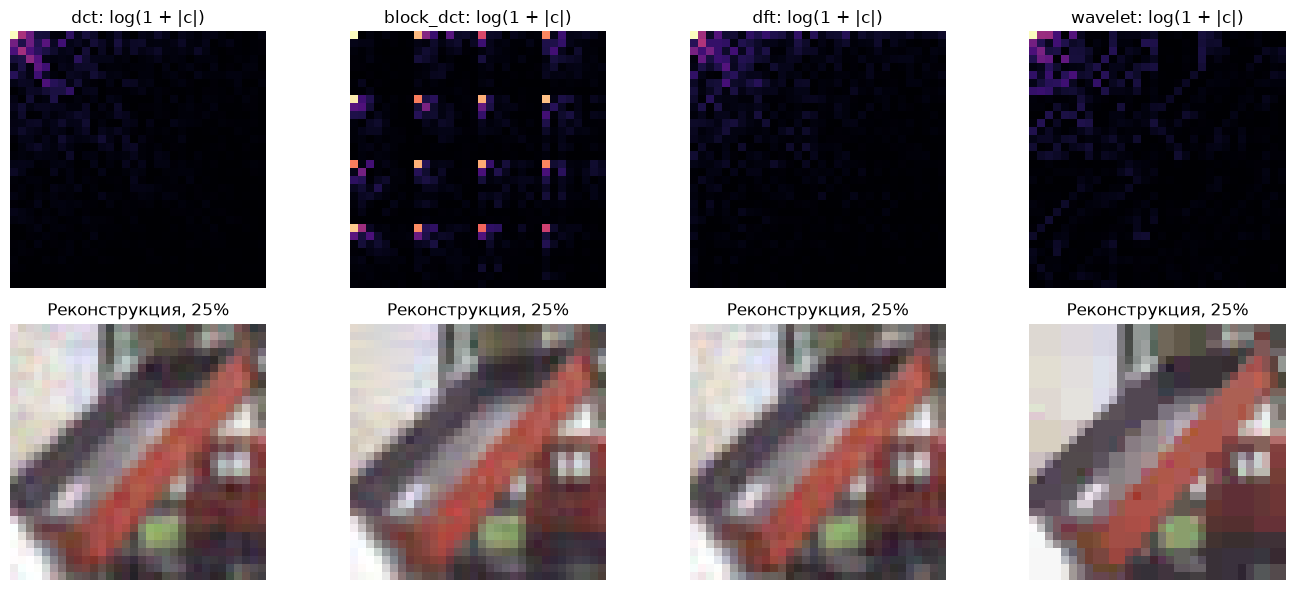

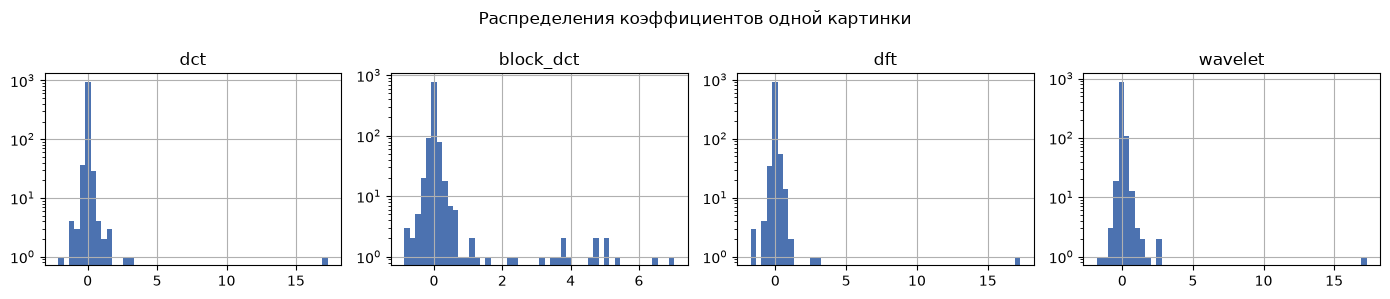

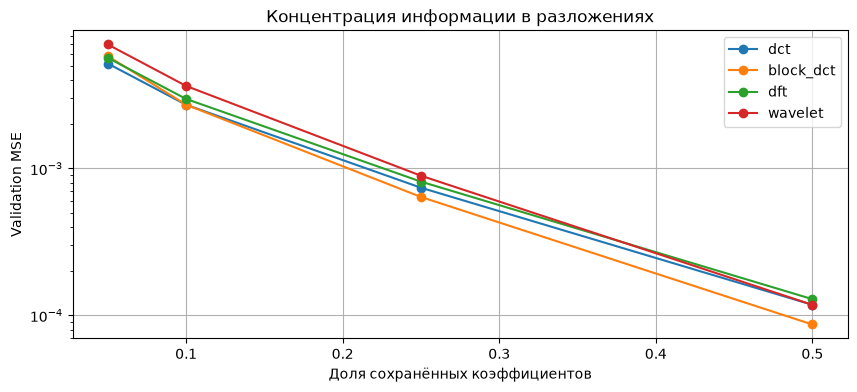

In [37]:
fig, axes = plt.subplots(2, len(DECOMPOSITIONS), figsize=(14, 6))
for column, name in enumerate(DECOMPOSITIONS):
    result = decomposition_results[name]
    axes[0, column].imshow(np.log1p(np.abs(result["coefficients"])), cmap="magma")
    axes[0, column].set_title(f"{name}: log(1 + |c|)")
    show_image(axes[1, column], result["examples"][0.25])
    axes[1, column].set_title("Реконструкция, 25%")
    axes[0, column].axis("off")
    axes[1, column].axis("off")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(DECOMPOSITIONS), figsize=(14, 3))
for ax, name in zip(axes, DECOMPOSITIONS):
    values = decomposition_results[name]["coefficients"].ravel()
    ax.hist(values, bins=50, color="#4c72b0")
    ax.set_title(name)
    ax.set_yscale("log")
fig.suptitle("Распределения коэффициентов одной картинки")
plt.tight_layout()
plt.show()

for name, result in decomposition_results.items():
    plt.plot(
        FRACTIONS,
        [result["mse_by_fraction"][f] for f in FRACTIONS],
        marker="o",
        label=name,
    )
plt.yscale("log")
plt.xlabel("Доля сохранённых коэффициентов")
plt.ylabel("Validation MSE")
plt.title("Концентрация информации в разложениях")
plt.legend()
plt.show()

### Концентрация коэффициентов в среднем по train


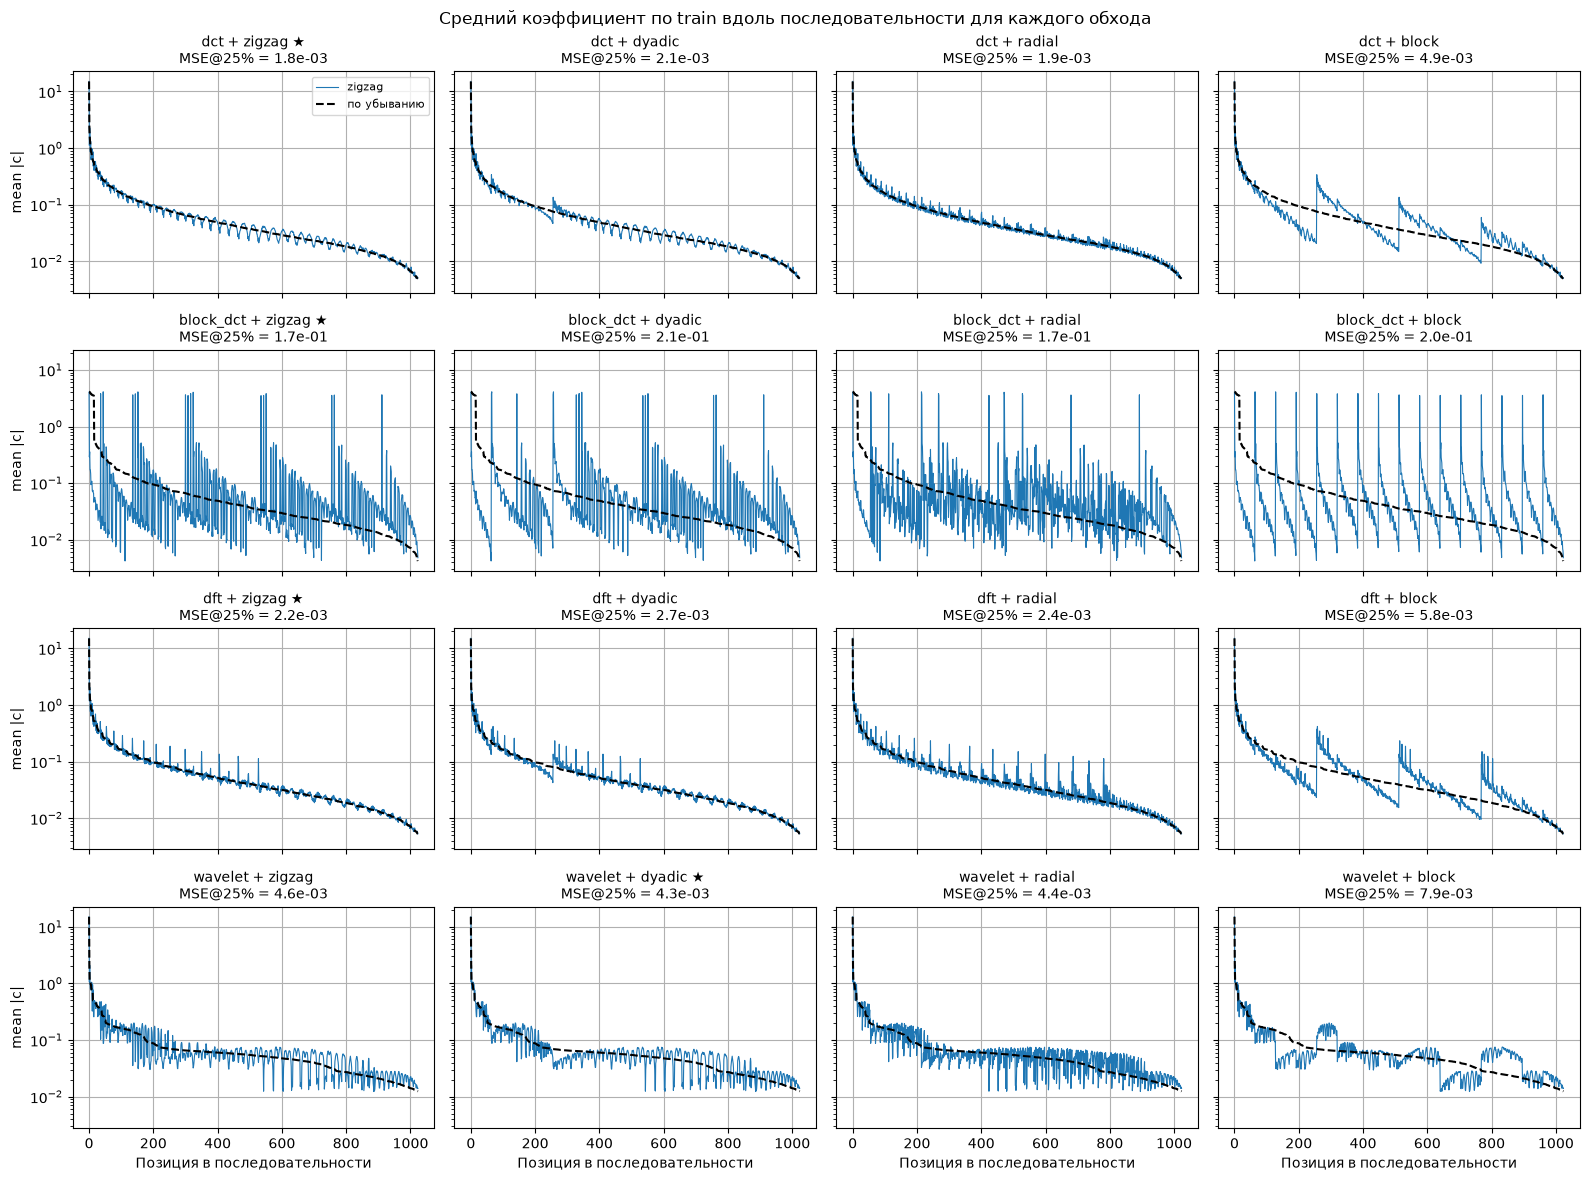

In [38]:
EPS = 1e-4
orders = {
    ordering: ordering_indices(
        ordering, height, width, **({"block_size": BLOCK_SIZE} if ordering == "block" else {})
    )
    for ordering in ORDERINGS
}
mean_abs_coeffs = {}
prefix_mse = {}
for name in DECOMPOSITIONS:
    params = {"block_size": BLOCK_SIZE} if name == "block_dct" else {}
    decomposition = get_decomposition(name, **params)
    mean_abs_coeffs[name] = np.abs(decomposition.forward(train_images)).mean(axis=(0, 1))
    coeffs = decomposition.forward(val_images)
    for ordering, indices in orders.items():
        restored = decomposition.inverse(reconstruct_prefix(coeffs, indices, 0.25))
        prefix_mse[name, ordering] = mse(val_images, restored)

log_means = {name: np.log10(mean + EPS) for name, mean in mean_abs_coeffs.items()}
vmin = min(value.min() for value in log_means.values())
vmax = max(value.max() for value in log_means.values())

fig, axes = plt.subplots(
    len(DECOMPOSITIONS), len(ORDERINGS), figsize=(16, 12), sharex=True, sharey=True
)
for row, name in enumerate(DECOMPOSITIONS):
    mean = mean_abs_coeffs[name]
    best = min(ORDERINGS, key=lambda ordering: prefix_mse[name, ordering])
    for column, ordering in enumerate(ORDERINGS):
        ax = axes[row, column]
        ax.semilogy(forward_ordering(mean, orders[ordering]) + EPS, lw=0.8, label=ordering)
        ax.semilogy(
            np.sort(mean.ravel())[::-1] + EPS, color="black", ls="--", label="по убыванию"
        )
        star = " ★" if ordering == best else ""
        ax.set_title(
            f"{name} + {ordering}{star}\nMSE@25% = {prefix_mse[name, ordering]:.1e}",
            fontsize=10,
        )
    axes[row, 0].set_ylabel("mean |c|")
for ax in axes[-1]:
    ax.set_xlabel("Позиция в последовательности")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Средний коэффициент по train вдоль последовательности для каждого обхода")
plt.tight_layout()
plt.show()

In [39]:
SELECTED_DECOMPOSITION = min(prefix_mse, key=prefix_mse.get)[0]
selected_decomposition_params = (
    {"block_size": BLOCK_SIZE} if SELECTED_DECOMPOSITION == "block_dct" else {}
)
selected_decomposition = get_decomposition(
    SELECTED_DECOMPOSITION, **selected_decomposition_params
)
train_coeffs = selected_decomposition.forward(train_images)
val_coeffs = selected_decomposition.forward(val_images)
print(f"Разложение-победитель по MSE@25% префикса: {SELECTED_DECOMPOSITION}")

Разложение-победитель по MSE@25% префикса: dct


## 3. Порядки

In [40]:
height, width = val_coeffs.shape[-2:]
ordering_results = {}
for name in ORDERINGS:
    params = {"block_size": BLOCK_SIZE} if name == "block" else {}
    indices = ordering_indices(name, height, width, **params)
    mse_by_fraction = {}
    examples = {}
    for fraction in FRACTIONS:
        partial_coeffs = reconstruct_prefix(val_coeffs, indices, fraction)
        restored = selected_decomposition.inverse(partial_coeffs)
        mse_by_fraction[fraction] = mse(val_images, restored)
        examples[fraction] = restored[0]
    position_map = np.empty(height * width, dtype=int)
    position_map[indices] = np.arange(height * width)
    ordering_results[name] = {
        "indices": indices,
        "position_map": position_map.reshape(height, width),
        "mse_by_fraction": mse_by_fraction,
        "examples": examples,
    }

selected_ordering = min(
    ORDERINGS, key=lambda name: ordering_results[name]["mse_by_fraction"][0.25]
)
print("Порядок       MSE при 25%  Победитель")
for name, result in ordering_results.items():
    winner = "★" if name == selected_ordering else ""
    print(f"{name:10s} {result['mse_by_fraction'][0.25]:12.6f}  {winner}")
print(f"\nВыбранный порядок: {selected_ordering}")

Порядок       MSE при 25%  Победитель
zigzag         0.001826  ★
dyadic         0.002093  
radial         0.001877  
block          0.004915  

Выбранный порядок: zigzag


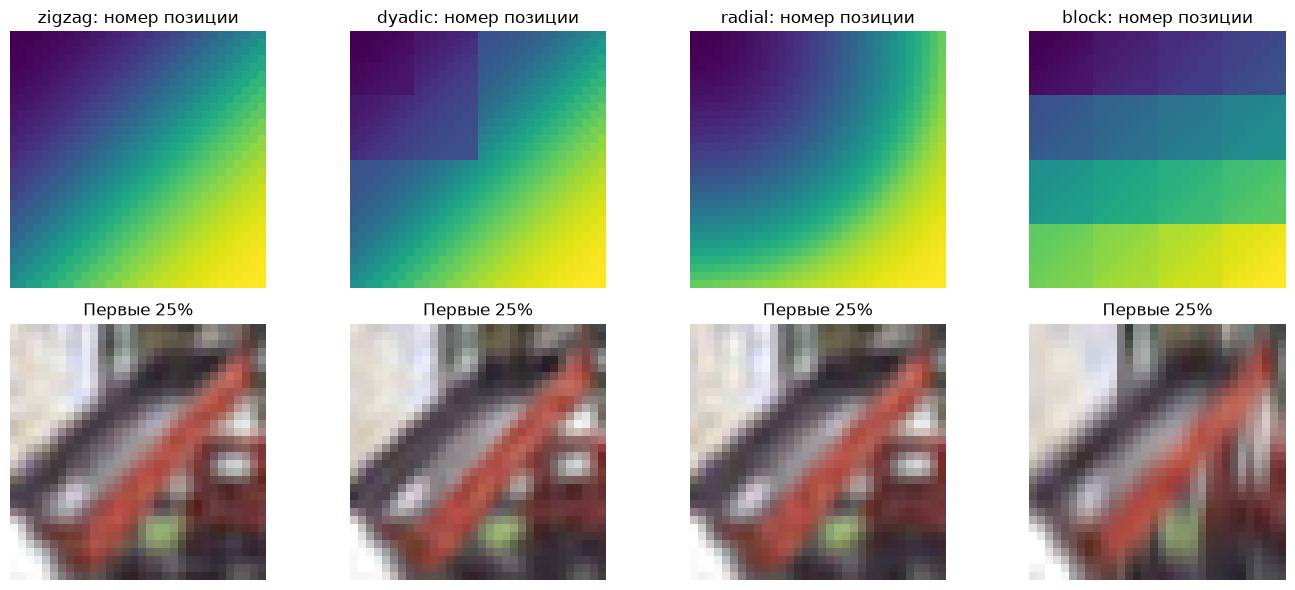

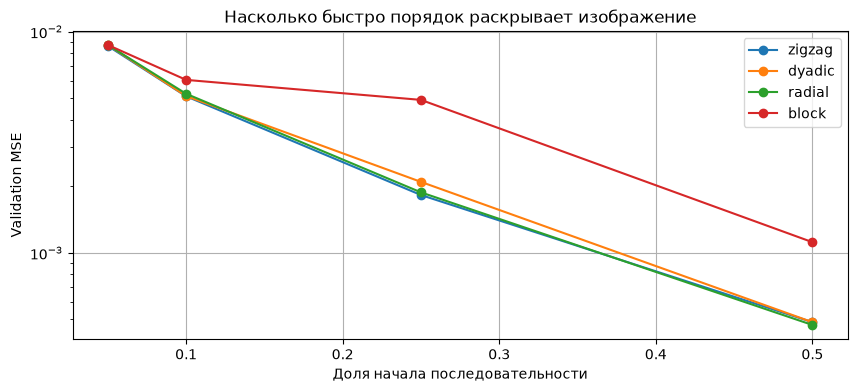

In [41]:
fig, axes = plt.subplots(2, len(ORDERINGS), figsize=(14, 6))
for column, name in enumerate(ORDERINGS):
    result = ordering_results[name]
    axes[0, column].imshow(result["position_map"], cmap="viridis")
    axes[0, column].set_title(f"{name}: номер позиции")
    show_image(axes[1, column], result["examples"][0.25])
    axes[1, column].set_title("Первые 25%")
    axes[0, column].axis("off")
    axes[1, column].axis("off")
plt.tight_layout()
plt.show()

for name, result in ordering_results.items():
    plt.plot(
        FRACTIONS,
        [result["mse_by_fraction"][f] for f in FRACTIONS],
        marker="o",
        label=name,
    )
plt.yscale("log")
plt.xlabel("Доля начала последовательности")
plt.ylabel("Validation MSE")
plt.title("Насколько быстро порядок раскрывает изображение")
plt.legend()
plt.show()

## 4. Нормализация

In [42]:
ordering_params = {"block_size": BLOCK_SIZE} if selected_ordering == "block" else {}
selected_indices = ordering_indices(selected_ordering, height, width, **ordering_params)
train_sequences = forward_ordering(train_coeffs, selected_indices).reshape(
    len(train_images), -1
)
val_sequences = forward_ordering(val_coeffs, selected_indices).reshape(
    len(val_images), -1
)


def sequences_to_images(sequences: np.ndarray) -> np.ndarray:
    ordered = np.asarray(sequences).reshape(len(sequences), channels, height * width)
    coeffs = invert_ordering(ordered, selected_indices, height, width)
    return selected_decomposition.inverse(coeffs)

In [43]:
normalization_results = {}
for transform in TRANSFORMS:
    for scaling in SCALINGS:
        for per_position in (False, True):
            key = (transform, scaling, per_position)
            config = {
                "transform": transform,
                "log_scale": 255.0,
                "scaling": scaling,
                "per_position": per_position,
            }
            normalizer = Normalizer(**config).fit(train_sequences)
            train_normalized = normalizer(train_sequences)
            val_normalized = normalizer(val_sequences)
            quantizer = Quantizer(num_bins=64, per_position=False).fit(train_normalized)
            restored_sequences = normalizer.inverse(
                quantizer.decode(quantizer.encode(val_normalized))
            )
            restored_images = sequences_to_images(restored_sequences)
            normalization_results[key] = {
                "config": config,
                "mse": mse(val_images, restored_images),
                "psnr": psnr(val_images, restored_images),
                "sample": val_normalized[:, :32].ravel(),
            }

best_normalization_key = min(
    normalization_results, key=lambda key: normalization_results[key]["mse"]
)
selected_normalization = {
    "key": best_normalization_key,
    "config": normalization_results[best_normalization_key]["config"],
}
print("transform   scaling  per_position       MSE      PSNR  Победитель")
for key, result in normalization_results.items():
    winner = "★" if key == best_normalization_key else ""
    print(
        f"{key[0]:10s} {key[1]:8s} {str(key[2]):12s} "
        f"{result['mse']:.6f} {result['psnr']:8.2f}  {winner}"
    )
print(f"\nВыбрана нормализация: {best_normalization_key}")

transform   scaling  per_position       MSE      PSNR  Победитель
none       minmax   False        0.077409    11.11  
none       minmax   True         0.000104    39.84  ★
none       standard False        0.077409    11.11  
none       standard True         0.000846    30.72  
signed_log minmax   False        0.001745    27.58  
signed_log minmax   True         0.000241    36.18  
signed_log standard False        0.001745    27.58  
signed_log standard True         0.001958    27.08  

Выбрана нормализация: ('none', 'minmax', True)


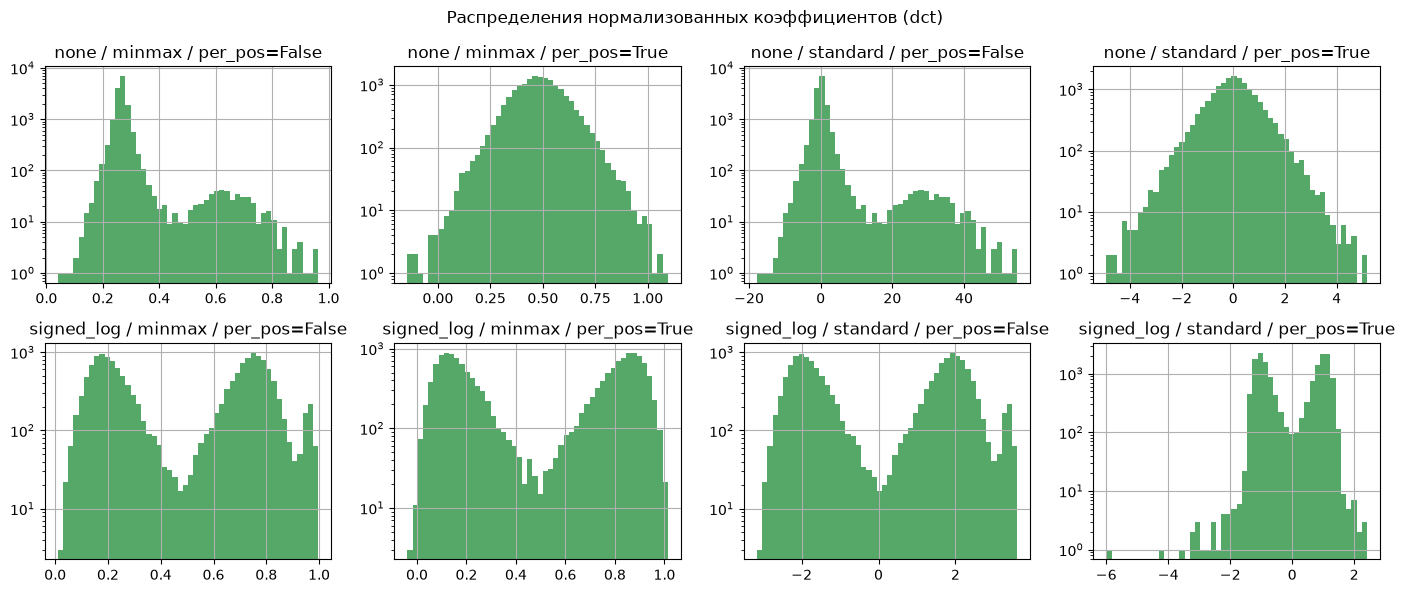

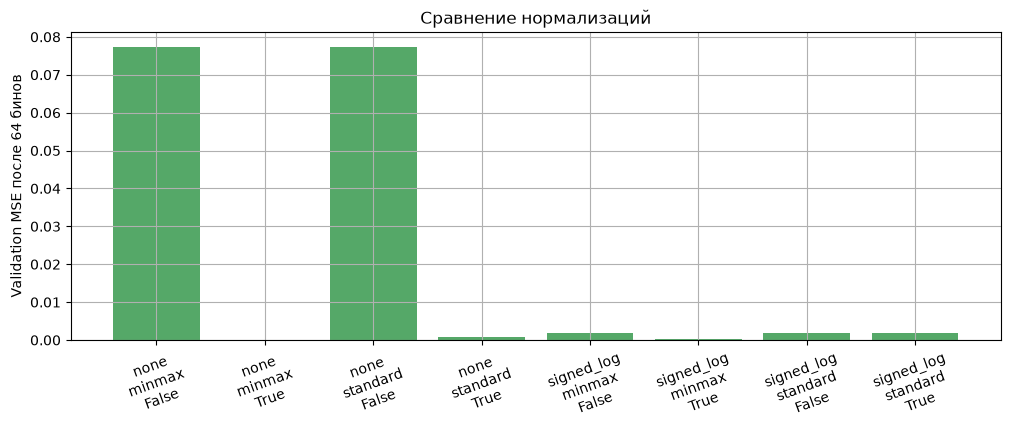

In [44]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (key, result) in zip(axes.flat, normalization_results.items()):
    ax.hist(result["sample"], bins=50, color="#55a868")
    ax.set_title(f"{key[0]} / {key[1]} / per_pos={key[2]}")
    ax.set_yscale("log")
fig.suptitle(f"Распределения нормализованных коэффициентов ({SELECTED_DECOMPOSITION})")
plt.tight_layout()
plt.show()

labels = [f"{key[0]}\n{key[1]}\n{key[2]}" for key in normalization_results]
values = [result["mse"] for result in normalization_results.values()]
plt.figure(figsize=(12, 4))
plt.bar(labels, values, color="#55a868")
plt.ylabel("Validation MSE после 64 бинов")
plt.title("Сравнение нормализаций")
plt.xticks(rotation=20)
plt.show()

### Выбранная нормализация

`selected_normalization` хранит конфигурацию с минимальной validation MSE.

## 5. Квантизация

In [45]:
selected_normalizer = Normalizer(**selected_normalization["config"]).fit(
    train_sequences
)
train_normalized = selected_normalizer(train_sequences)
val_normalized = selected_normalizer(val_sequences)
BIN_COUNTS = (16, 32, 64, 128, 256)
quantization_results = {}
for num_bins in BIN_COUNTS:
    for per_position in (False, True):
        key = (num_bins, per_position)
        quantizer = Quantizer(num_bins=num_bins, per_position=per_position).fit(
            train_normalized
        )
        tokens = quantizer.encode(val_normalized)
        restored_sequences = selected_normalizer.inverse(quantizer.decode(tokens))
        restored_images = sequences_to_images(restored_sequences)
        quantization_results[key] = {
            "config": {
                "method": "uniform",
                "num_bins": num_bins,
                "per_position": per_position,
            },
            "mse": mse(val_images, restored_images),
            "psnr": psnr(val_images, restored_images),
            "token_min": int(tokens.min()),
            "token_max": int(tokens.max()),
        }

best_quantization_key = min(
    quantization_results, key=lambda key: quantization_results[key]["mse"]
)
selected_quantization = {
    "key": best_quantization_key,
    "config": quantization_results[best_quantization_key]["config"],
}
print("bins  per_position       MSE      PSNR  token range  Победитель")
for key, result in quantization_results.items():
    winner = "★" if key == best_quantization_key else ""
    print(
        f"{key[0]:4d}  {str(key[1]):12s} {result['mse']:.6f} "
        f"{result['psnr']:8.2f}  [{result['token_min']}, {result['token_max']}]  {winner}"
    )
print(f"\nВыбрана квантизация: {best_quantization_key}")

bins  per_position       MSE      PSNR  token range  Победитель
  16  False        0.001347    28.71  [0, 15]  
  16  True         0.001347    28.71  [0, 15]  
  32  False        0.000356    34.48  [0, 31]  
  32  True         0.000356    34.48  [0, 31]  
  64  False        0.000104    39.84  [0, 63]  
  64  True         0.000104    39.84  [0, 63]  
 128  False        0.000040    43.96  [0, 127]  
 128  True         0.000040    43.96  [0, 127]  
 256  False        0.000024    46.21  [0, 255]  ★
 256  True         0.000024    46.21  [0, 255]  

Выбрана квантизация: (256, False)


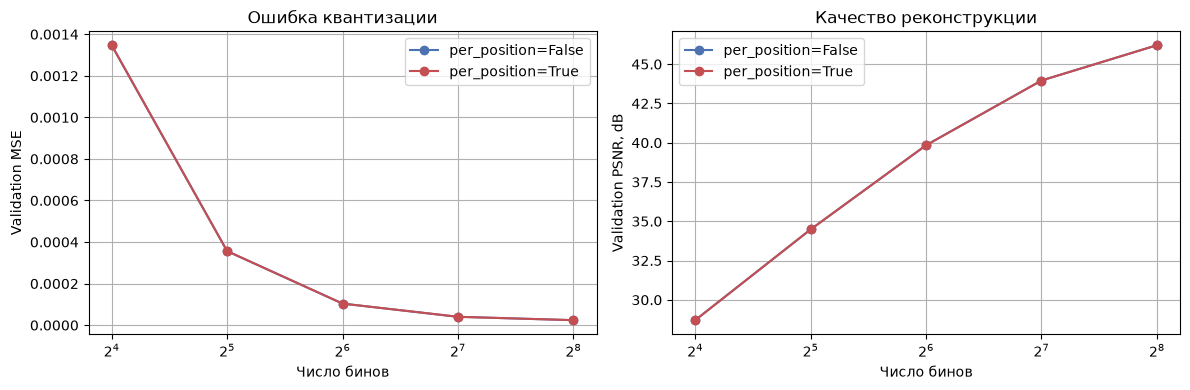

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for per_position, color in ((False, "#4c72b0"), (True, "#c44e52")):
    errors = [quantization_results[(bins, per_position)]["mse"] for bins in BIN_COUNTS]
    quality = [
        quantization_results[(bins, per_position)]["psnr"] for bins in BIN_COUNTS
    ]
    label = f"per_position={per_position}"
    axes[0].plot(BIN_COUNTS, errors, marker="o", color=color, label=label)
    axes[1].plot(BIN_COUNTS, quality, marker="o", color=color, label=label)
axes[0].set(xlabel="Число бинов", ylabel="Validation MSE", title="Ошибка квантизации")
axes[1].set(
    xlabel="Число бинов", ylabel="Validation PSNR, dB", title="Качество реконструкции"
)
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.legend()
plt.tight_layout()
plt.show()

### Выбранная квантизация

`selected_quantization` — конфигурация с минимальной validation MSE.

## 6. Итоговый токенизатор

In [47]:
final_ordering_params = {"block_size": BLOCK_SIZE} if selected_ordering == "block" else {}
final_config = TokenizerConfig(
    decomposition=SELECTED_DECOMPOSITION,
    decomposition_params=selected_decomposition_params,
    ordering=selected_ordering,
    ordering_params=final_ordering_params,
    normalization=selected_normalization["config"],
    quantization=selected_quantization["config"],
)
final_tokenizer = Tokenizer(final_config).fit(train_images)
test_tokens = final_tokenizer.encode(test_images)
test_reconstruction = final_tokenizer.decode(test_tokens)
final_metrics = {
    "mse": mse(test_images, test_reconstruction),
    "psnr": psnr(test_images, test_reconstruction),
}

assert np.issubdtype(test_tokens.dtype, np.integer)
assert test_tokens.shape == (len(test_images), channels * height * width)
assert 0 <= test_tokens.min() <= test_tokens.max() < final_tokenizer.vocab_size
assert test_reconstruction.shape == test_images.shape
assert np.isfinite(test_reconstruction).all()

print("Итоговая конфигурация")
print(f"  разложение:   {SELECTED_DECOMPOSITION}")
print(f"  порядок:      {selected_ordering}")
print(f"  нормализация: {selected_normalization['key']}")
print(f"  квантизация:  {selected_quantization['key']}")
print(f"  длина:        {final_tokenizer.sequence_length} токенов")
print(f"  словарь:      {final_tokenizer.vocab_size} токенов")
print(f"  test MSE:     {final_metrics['mse']:.6f}")
print(f"  test PSNR:    {final_metrics['psnr']:.2f} dB")
print(f"\nПервые 32 токена первой test-картинки: {test_tokens[0, :32].tolist()}")

Итоговая конфигурация
  разложение:   dct
  порядок:      zigzag
  нормализация: ('none', 'minmax', True)
  квантизация:  (256, False)
  длина:        3072 токенов
  словарь:      256 токенов
  test MSE:     0.000030
  test PSNR:    45.20 dB

Первые 32 токена первой test-картинки: [98, 195, 176, 109, 119, 114, 84, 127, 99, 149, 147, 149, 137, 122, 83, 118, 112, 142, 146, 66, 155, 143, 141, 133, 84, 87, 135, 101, 128, 165, 99, 157]


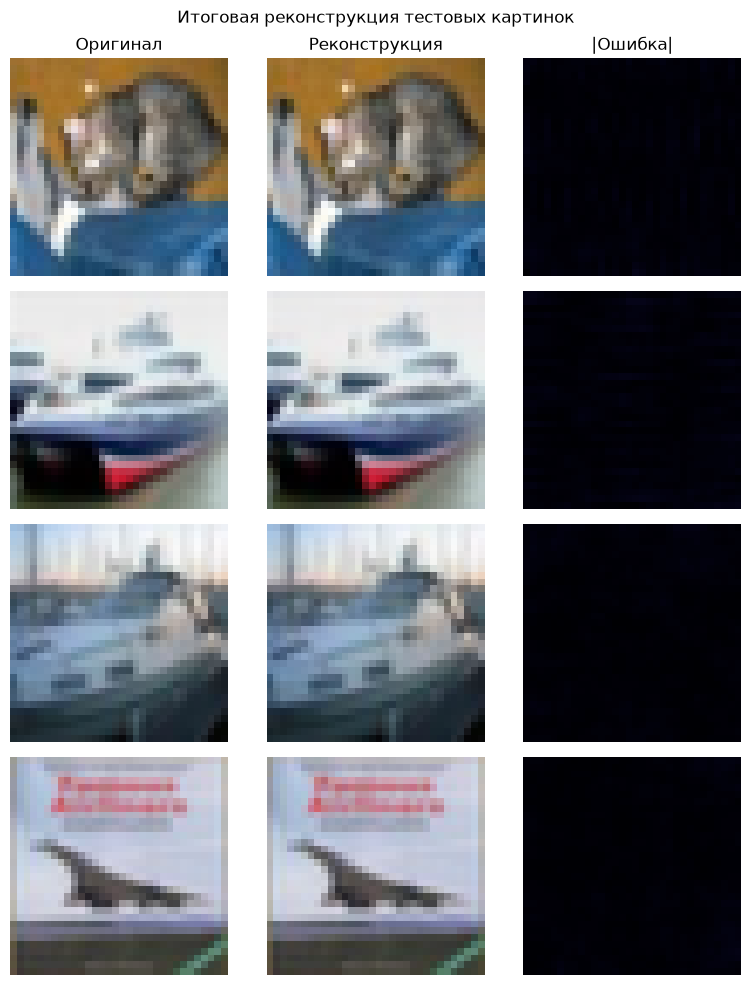

In [48]:
fig, axes = plt.subplots(4, 3, figsize=(8, 10))
for row in range(4):
    original = test_images[row]
    restored = test_reconstruction[row]
    absolute_error = np.abs(original - restored).mean(axis=0)
    show_image(axes[row, 0], original)
    show_image(axes[row, 1], restored)
    axes[row, 2].imshow(
        absolute_error,
        cmap="inferno",
        vmin=0,
        vmax=max(0.15, float(absolute_error.max())),
    )
    for ax in axes[row]:
        ax.axis("off")
for ax, title in zip(axes[0], ("Оригинал", "Реконструкция", "|Ошибка|")):
    ax.set_title(title)
fig.suptitle("Итоговая реконструкция тестовых картинок")
plt.tight_layout()
plt.show()